# RetailRocket · следующий просмотр
Первая контрольная точка. Проверяем, дают ли совпадающие интервалы активности товаров информацию сверх популярности. Вход — оригинальный `data/events.csv`. Запускайте ячейки сверху вниз из корня проекта или каталога notebooks. Нужны Python, NumPy и pandas.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd

SEED = 42
MAX_USERS = 1000  # На каждый период. None включает всех пользователей.
DAY = 86_400_000
RANK = 16
HISTORY = 20
path = next(p for p in (Path("data/events.csv"), Path("../data/events.csv")) if p.exists())
raw = pd.read_csv(path, usecols=["timestamp", "visitorid", "event", "itemid"])
print(platform.python_version(), np.__version__, pd.__version__)
print(raw.event.value_counts())
views = raw.loc[raw.event.eq("view"), ["timestamp", "visitorid", "itemid"]].sort_values("timestamp", kind="stable")
del raw
times, users, items = (views[c].to_numpy() for c in views)
start, end = times[0], times[-1] + 1
bounds = start + (end - start) * np.array([0, 40, 80, 90, 100]) // 100
cuts = times.searchsorted(bounds)
prefix = cuts[1]
catalog = np.unique(items[:prefix])
ids = pd.Index(catalog).get_indexer(items)
print("Границы UTC:", pd.to_datetime(bounds, unit="ms", utc=True).tolist())

3.13.5 2.3.5 2.2.3
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


Границы UTC: [Timestamp('2015-05-03 03:00:11.289000+0000', tz='UTC'), Timestamp('2015-06-27 07:48:01.889000+0000', tz='UTC'), Timestamp('2015-08-21 12:35:52.489000+0000', tz='UTC'), Timestamp('2015-09-04 07:47:50.139000+0000', tz='UTC'), Timestamp('2015-09-18 02:59:47.789000+0000', tz='UTC')]


## Покрытие и история
Разбиение по длительности. Каталог фиксируем до T0. Последующие просмотры обновляют историю и популярность. Покрытие считаем на всех событиях каждого периода.

In [2]:
for period, lo, hi in zip(["prefix", "train", "validation", "test"], cuts[:-1], cuts[1:]):
    lengths = pd.Series(users[lo:hi]).value_counts()
    outside = ids[lo:hi] < 0
    print(period, dict(views=hi-lo, users=len(lengths), items=len(np.unique(items[lo:hi])),
                       outside_events=round(outside.mean(), 4),
                       outside_unique=round(len(np.unique(items[lo:hi][outside])) / len(np.unique(items[lo:hi])), 4),
                       user_length_p50_p90=lengths.quantile([.5, .9]).tolist()))

prefix {'views': np.int64(1092810), 'users': 570420, 'items': 158025, 'outside_events': np.float64(0.0), 'outside_unique': 0.0, 'user_length_p50_p90': [1.0, 3.0]}
train {'views': np.int64(1098497), 'users': 609225, 'items': 160619, 'outside_events': np.float64(0.121), 'outside_unique': 0.3578, 'user_length_p50_p90': [1.0, 3.0]}


validation {'views': np.int64(237412), 'users': 140969, 'items': 72585, 'outside_events': np.float64(0.1551), 'outside_unique': 0.2639, 'user_length_p50_p90': [1.0, 3.0]}
test {'views': np.int64(235593), 'users': 139694, 'items': 71622, 'outside_events': np.float64(0.1862), 'outside_unique': 0.2822, 'user_length_p50_p90': [1.0, 3.0]}


In [3]:
def activity(hours):
    width = hours * DAY // 24
    bins = (times[:prefix] - start) // width
    count = int((bounds[1] - start + width - 1) // width)
    matrix = np.zeros((len(catalog), count), dtype=np.uint8)
    matrix[ids[:prefix], bins] = 1
    return matrix

for hours in [6, 24]:
    X = activity(hours)
    active = X.sum(axis=1)
    print(hours, "ч", X.shape, "плотность", round(X.mean(), 4),
          "доля с одним интервалом", round((active == 1).mean(), 4),
          "доля активных в ≥90% интервалов", round((active >= .9 * X.shape[1]).mean(), 4))

6 ч (158025, 221) плотность 0.0231 доля с одним интервалом 0.423 доля активных в ≥90% интервалов 0.0
24 ч (158025, 56) плотность 0.0764 доля с одним интервалом 0.4297 доля активных в ≥90% интервалов 0.0011


## Представления и контроли
Основная спецификация заранее фиксирована: сутки, ранг 16, бинарный профиль. Для узкой матрицы вычисляем правые сингулярные векторы через XᵀX. Произведение XV даёт UΣ. Нормируем строки для косинусного скора. Независимая перестановка каждой строки сохраняет число активных дней товара. Случайный контроль имеет ту же размерность и единичные нормы. Проверяем совпадение периодов активности; порядок дней и сезонность требуют отдельных экспериментов.

In [4]:
def normalize(rows):
    return rows / np.maximum(np.linalg.norm(rows, axis=1, keepdims=True), 1e-12)

def embed(matrix):
    matrix = matrix.astype(np.float32)
    _, vectors = np.linalg.eigh(matrix.T @ matrix)
    return np.ascontiguousarray(normalize(matrix @ vectors[:, -RANK:]))

rng = np.random.default_rng(SEED)
z = embed(X)
shuffled = rng.permuted(X, axis=1)
assert np.array_equal(X.sum(axis=1), shuffled.sum(axis=1))
embeddings = {"SVD": z, "Shuffle": embed(shuffled),
              "Random": normalize(rng.standard_normal(z.shape, dtype=np.float32)) * np.linalg.norm(z, axis=1, keepdims=True)}

## Оценка каждого следующего просмотра
Для быстрого пилота равновероятно выбираем до 1000 пользователей из посетителей каждого периода и оцениваем все их цели внутри каталога. Популярность использует события всех посетителей. Все методы ранжируют полный каталог, повторы разрешены. История содержит последние 20 просмотров товаров из каталога строго до текущего timestamp. Для пустой истории используем RecentPopular во всех вариантах Temporal-pool.

Проекция единичная, усреднение равномерное. Фиксированный скор популярности равен сумме log1p общей и семидневной частоты. К нему добавляем косинус с нормированным средним истории с коэффициентом 1. Параметры заранее фиксированы, обучение проекции оставлено для следующего этапа. Равные скоры упорядочиваем по возрастанию itemid.

In [5]:
def target_rank(scores, target):
    value = scores[target]
    rank = 1 + np.count_nonzero(scores > value) + np.count_nonzero(scores[:target] == value)
    return rank

def evaluate(lo, hi, seed):
    visitors = np.unique(users[lo:hi])
    rng = np.random.default_rng(seed)
    selected = visitors if MAX_USERS is None else rng.choice(visitors, min(MAX_USERS, len(visitors)), replace=False)
    selected_rows = np.flatnonzero(np.isin(users[:hi], selected) & (ids[:hi] >= 0))
    histories = {}
    counts = np.zeros(len(catalog), dtype=np.int64)
    recent = counts.copy()
    last = left = 0
    rows = []
    cold = targets = 0
    for time, group in pd.Series(selected_rows, index=times[selected_rows]).groupby(level=0, sort=False):
        positions = group.to_numpy()
        if positions[0] >= lo:
            stop = times.searchsorted(time)
            window = times.searchsorted(time - 7 * DAY)
            added = ids[last:stop]
            expired = ids[left:window]
            np.add.at(counts, added[added >= 0], 1)
            np.add.at(recent, added[added >= 0], 1)
            np.subtract.at(recent, expired[expired >= 0], 1)
            last, left = stop, window
            pop = np.log1p(counts) + np.log1p(recent)
            for pos in positions:
                user, target = users[pos], ids[pos]
                history = histories.get(user, [])
                targets += 1
                cold += int(len(history) == 0)
                scores = {"MostPopular": counts, "RecentPopular": recent, "Pop": pop}
                for name, vectors in embeddings.items():
                    if history:
                        profile = vectors[history].mean(axis=0)
                        similarity = vectors @ (profile / max(np.linalg.norm(profile), 1e-12))
                        scores[name] = pop + similarity
                    else:
                        scores[name] = recent
                for name, values in scores.items():
                    rows.append((pos, user, bool(history), name, target_rank(values, target)))
        for pos in positions:
            history = histories.setdefault(users[pos], [])
            history.append(ids[pos])
            del history[:-HISTORY]
    frame = pd.DataFrame(rows, columns=["event", "user", "warm", "model", "rank"])
    frame["Recall@10"] = frame["rank"] <= 10
    frame["NDCG@10"] = np.where(frame["Recall@10"], 1 / np.log2(frame["rank"] + 1), 0.)
    per_user = frame.groupby(["user", "model"])[["Recall@10", "NDCG@10"]].mean()
    print("Выбрано пользователей:", len(selected), "с доступной целью:", frame.user.nunique(),
          "целей:", targets, "без истории:", cold)
    return per_user.groupby("model").mean(), frame

results, events = {}, {}
for label, lo, hi, seed in [("validation", cuts[2], cuts[3], SEED), ("test", cuts[3], cuts[4], SEED+1)]:
    print(label)
    results[label], events[label] = evaluate(lo, hi, seed)
    print(results[label].round(6))

validation


Выбрано пользователей: 1000 с доступной целью: 850 целей: 1400 без истории: 767
               Recall@10   NDCG@10
model                             
MostPopular     0.012235  0.008663
Pop             0.016353  0.010945
Random          0.018902  0.012069
RecentPopular   0.014882  0.010527
SVD             0.017529  0.011474
Shuffle         0.017529  0.011474
test


Выбрано пользователей: 1000 с доступной целью: 846 целей: 1370 без истории: 767
               Recall@10   NDCG@10
model                             
MostPopular     0.010807  0.006897
Pop             0.015929  0.008792
Random          0.015929  0.009629
RecentPopular   0.013987  0.008707
SVD             0.014156  0.008812
Shuffle         0.014156  0.008812


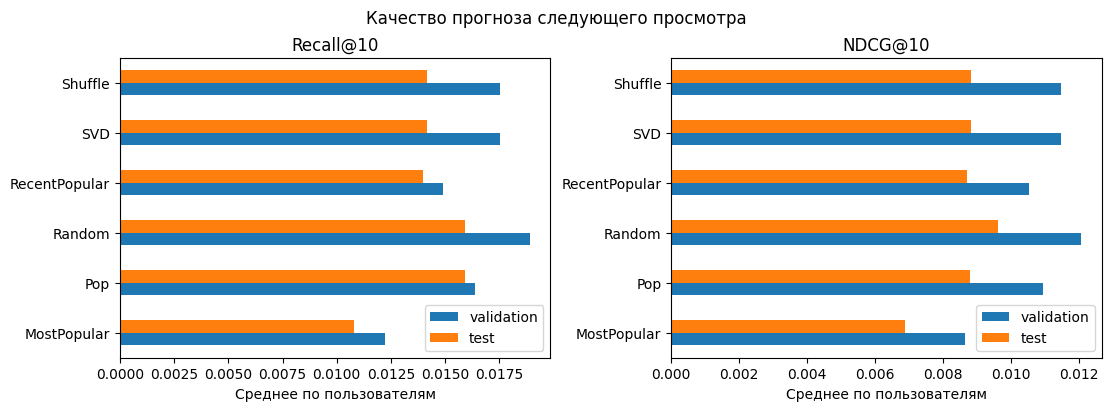

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, metric in zip(axes, ["Recall@10", "NDCG@10"]):
    pd.DataFrame({split: table[metric] for split, table in results.items()}).plot.barh(ax=ax)
    ax.set(title=metric, ylabel="", xlabel="Среднее по пользователям")
fig.suptitle("Качество прогноза следующего просмотра")
plt.show()

validation с историей: 633 ранг различается: 618 различается вклад в NDCG@10: 0 попаданий SVD / Shuffle: 6 6
test с историей: 603 ранг различается: 586 различается вклад в NDCG@10: 0 попаданий SVD / Shuffle: 3 3


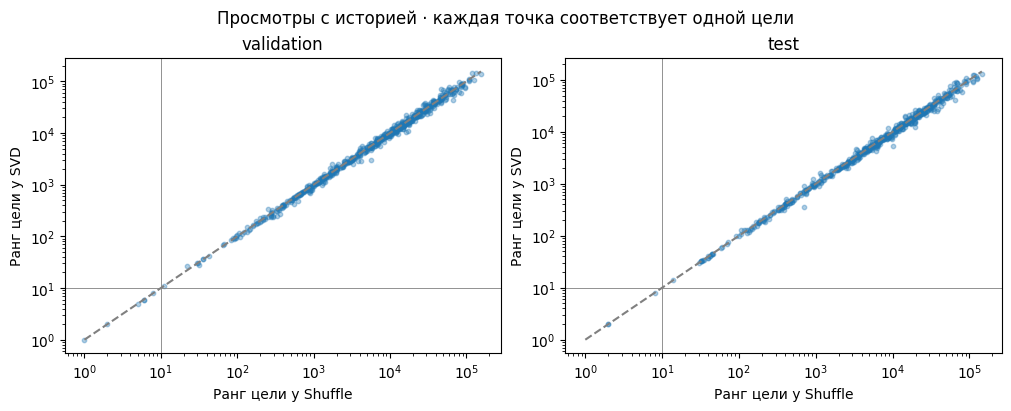

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (split, frame) in zip(axes, events.items()):
    ranks = frame.loc[frame.warm].pivot(index="event", columns="model", values="rank")
    svd, shuffle = ranks["SVD"], ranks["Shuffle"]
    changed = svd != shuffle
    visible = changed & ((svd <= 10) | (shuffle <= 10))
    print(split, "с историей:", len(ranks), "ранг различается:", changed.sum(),
          "различается вклад в NDCG@10:", visible.sum(),
          "попаданий SVD / Shuffle:", (svd <= 10).sum(), (shuffle <= 10).sum())
    ax.scatter(shuffle, svd, s=10, alpha=.35)
    limit = max(shuffle.max(), svd.max())
    ax.plot([1, limit], [1, limit], color="gray", linestyle="--")
    ax.axhline(10, color="gray", linewidth=.6)
    ax.axvline(10, color="gray", linewidth=.6)
    ax.set(xscale="log", yscale="log", title=split, xlabel="Ранг цели у Shuffle", ylabel="Ранг цели у SVD")
fig.suptitle("Просмотры с историей · каждая точка соответствует одной цели")
plt.show()

## Вывод по сохранённому прогону
В дневной матрице 42,97% товаров активны только в одном интервале. У 767 из 1370 оцениваемых тестовых просмотров отсутствует доступная история, поэтому все три варианта Temporal-pool выдают для них RecentPopular. На validation и test исходный и перемешанный SVD дали одинаковые агрегированные метрики до шести знаков. Этот пилот не выявил выигрыша от календарных совпадений. Для уточнения результата стоит расширить выборку пользователей, отдельно оценить просмотры с историей и построить парный доверительный интервал по пользователям.